# Group 05, Project 2, Deliverable 1: Baseline Modelling

**Course:** ACIT 4880, CRN 45883, Domain D (US imports and tariffs)
**Members:** Jashanpreet Singh, Priyanshu Batra, Janek Basi

**Business question (from P1 D1):** how did US imports of capital goods, automotive goods and consumer goods move through the 2025 tariff period, and how much of that movement came from price versus volume? Stakeholder: procurement and supply chain teams at US importers.

**Target:** `import_value_usd`, the monthly US general import value for one partner country and one 5 digit end-use product line. It is a continuous dollar amount with 222,258 distinct values, so we are a **regression group** and our three baseline algorithms are **Linear Regression, Ridge Regression and Lasso Regression**.

**Data:** `data/processed/d2_clean_pre_transform.csv.gz`, the cleaned P1 D2 output saved after outlier handling and before any transformation (277,592 rows, 22 columns).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.exceptions import ConvergenceWarning

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.width", 160)

df = pd.read_csv(
    "data/processed/d2_clean_pre_transform.csv.gz",
    parse_dates=["month"],
    dtype={"cty_code": str, "enduse_code": str, "category_code": str},
)
TARGET = "import_value_usd"
print("Loaded cleaned, untransformed dataset from P1 D2:", df.shape)
print("Target dtype:", df[TARGET].dtype, "| unique values:", df[TARGET].nunique(), "-> continuous, so this is a regression problem")
df.head(3)

Loaded cleaned, untransformed dataset from P1 D2: (277592, 22)
Target dtype: int64 | unique values: 222258 -> continuous, so this is a regression problem


,cty_code,country,enduse_code,enduse_desc,import_value_usd,consumption_value_usd,dutiable_value_usd,calculated_duty_usd,air_value_usd,vessel_value_usd,...,vessel_weight_kg,category_code,month,fred_series,price_index,category,price_index_missing,air_weight_kg_missing,vessel_weight_kg_missing,is_outlier_import_value
0,1220,Canada,20000,"Generators, Accessories",107499386,107923317,6909147,270810,7705117,46471,...,"3,029.0000",2,2022-01-01,IR2,91.4000,Capital goods,0,0,0,1
1,2010,Mexico,20000,"Generators, Accessories",621390284,617165194,59181356,2013272,12922581,452706,...,"56,175.0000",2,2022-01-01,IR2,91.4000,Capital goods,0,0,0,1
2,2050,Guatemala,20000,"Generators, Accessories",109662,109662,0,0,109662,0,...,0.0000,2,2022-01-01,IR2,91.4000,Capital goods,0,0,0,0


# Part 1: Feature Construction

We rebuild the four readable columns from P1 D3 and add a time index:
- `effective_tariff_rate`: duty paid as a share of the goods' value (a rate, not a dollar amount)
- `pays_duty`: 1 if any duty was paid
- `main_mode`: the transport mode that carried most of the value (Vessel, Air, Land and other)
- `months_since_start`: 0 for Jan 2022 up to 54 for Jul 2026, so the models can pick up a time trend

In [2]:
# Same derived columns as P1 D3, plus a time index
df["effective_tariff_rate"] = np.where(
    df["consumption_value_usd"] > 0,
    df["calculated_duty_usd"] / df["consumption_value_usd"].replace(0, np.nan),
    0.0,
)
df["pays_duty"] = (df["calculated_duty_usd"] > 0).astype(int)
df["main_mode"] = np.select(
    [(df["vessel_value_usd"] >= df["air_value_usd"]) & (df["vessel_value_usd"] > 0), df["air_value_usd"] > 0],
    ["Vessel", "Air"],
    "Land and other",
)
df["months_since_start"] = (df["month"].dt.year - 2022) * 12 + df["month"].dt.month - 1
print(df[["effective_tariff_rate", "pays_duty", "months_since_start"]].describe().T)
print(df["main_mode"].value_counts())

                             count    mean     std    min     25%     50%     75%     max
effective_tariff_rate 277,592.0000  0.0554  0.0865 0.0000  0.0000  0.0149  0.0980  2.0000
pays_duty             277,592.0000  0.7243  0.4469 0.0000  0.0000  1.0000  1.0000  1.0000
months_since_start    277,592.0000 26.8980 15.8873 0.0000 13.0000 27.0000 41.0000 54.0000
main_mode
Air               141015
Vessel            130950
Land and other      5627
Name: count, dtype: int64


### Leakage check

The handout defines leakage as a column that is computed from or directly encodes the target. In P1 D3 we only removed `consumption_value_usd`, because its correlation with the target was 0.997. Looking at how the Census reports these columns, several others are also pieces of the same import dollars, so the check below tests that directly.

In [3]:
# Evidence for the leakage decisions: are these columns pieces of the target's own dollars?
mode_sum = df["air_value_usd"] + df["vessel_value_usd"]
checks = pd.DataFrame({
    "check": [
        "air_value + vessel_value <= import_value",
        "container_value <= vessel_value",
        "dutiable_value <= import_value",
        "is_outlier_import_value set only when target is extreme",
    ],
    "share of rows where true": [
        (mode_sum <= df[TARGET] * 1.001).mean(),
        (df["container_value_usd"] <= df["vessel_value_usd"] * 1.001).mean(),
        (df["dutiable_value_usd"] <= df[TARGET] * 1.001).mean(),
        (df.loc[df["is_outlier_import_value"] == 1, TARGET] > df[TARGET].quantile(0.75)).mean(),
    ],
})
display(checks)
leak_cols = ["consumption_value_usd", "air_value_usd", "vessel_value_usd", "container_value_usd",
             "dutiable_value_usd", "calculated_duty_usd", "is_outlier_import_value"]
print("Correlation of each leakage candidate with the target:")
print(df[leak_cols].corrwith(df[TARGET]).round(3).sort_values(ascending=False))

,check,share of rows where true
0,air_value + vessel_value <= import_value,1.0000
1,container_value <= vessel_value,1.0000
2,dutiable_value <= import_value,0.9733
3,is_outlier_import_value set only when target i...,1.0000


Correlation of each leakage candidate with the target:
consumption_value_usd     0.9970
air_value_usd             0.7140
vessel_value_usd          0.5530
dutiable_value_usd        0.5130
container_value_usd       0.4850
calculated_duty_usd       0.4070
is_outlier_import_value   0.3010
dtype: float64


**What the check shows:**
- `air_value_usd + vessel_value_usd` never exceeds the target, in **100% of rows**. Both are slices of the import value split by transport mode (the remainder is land and other). If we kept them, the model would just add up the pieces of the answer. This is the same situation as `fare` and `tip` inside `trip_total` in the handout's Domain E example.
- `container_value_usd` never exceeds `vessel_value_usd` (100% of rows), so it is a slice of a slice.
- `dutiable_value_usd` is at or below the target in 97.3% of rows. It is the taxable portion of the target, and the rest is the duty-free portion.
- `calculated_duty_usd` is rate × dutiable value, so it grows with the target's dollars. We keep the **rate** (`effective_tariff_rate`) and drop the **dollar amount**, because the rate carries the tariff information without encoding how big the shipment was.
- `is_outlier_import_value` is a D2 flag that is 1 only when the target is beyond the IQR fence, so it is computed directly from the target.

These seven columns have correlations with the target from 0.301 to 0.997. In P1 D3 we kept air and vessel value as features, so this is a correction for modelling: those correlations were real, but for the wrong reason.

In [4]:
NUMERIC = [
    "air_weight_kg", "vessel_weight_kg",          # physical shipment size (kg), not dollars
    "price_index",                                # BLS import price index for the category
    "effective_tariff_rate", "pays_duty",         # tariff exposure as a rate / flag, not a dollar amount
    "air_weight_kg_missing", "vessel_weight_kg_missing",  # D2 imputation flags
    "months_since_start",                         # time trend
]
CATEGORICAL = ["category", "main_mode"]

EXCLUDED = {
    "consumption_value_usd": "LEAKAGE: same shipments valued at entry for consumption; r = 0.997 with the target, it is the answer in different packaging",
    "air_value_usd": "LEAKAGE: the air-freight slice of the target's own dollars (air + vessel never exceeds the target)",
    "vessel_value_usd": "LEAKAGE: the ocean-freight slice of the target's own dollars",
    "container_value_usd": "LEAKAGE: a subset of vessel_value_usd, so also a piece of the target",
    "dutiable_value_usd": "LEAKAGE: the taxable share of the target's dollars (dutiable + duty-free = import value)",
    "calculated_duty_usd": "LEAKAGE: computed as rate x dutiable value, so it scales with the target; the rate itself is kept as effective_tariff_rate",
    "is_outlier_import_value": "LEAKAGE: a D2 flag computed from the target itself (1 when import value is beyond the IQR fence)",
    "cty_code": "Identifier; duplicates country",
    "country": "233-level label; one-hot would add 232 sparse columns to a 13-feature baseline, kept for Project 2 D2",
    "enduse_code": "Identifier for the 5-digit product line, too many levels for a baseline linear model",
    "enduse_desc": "Text label of enduse_code, duplicates it",
    "category_code": "Duplicates category (2/3/4)",
    "fred_series": "Duplicates category (IR2/IR3/IR4 maps 1 to 1)",
    "month": "Raw date; replaced by the numeric months_since_start",
    "price_index_missing": "D2 imputation flag that is 0 for every training row (the only imputed month is Oct 2025, which falls in the test set), so the model cannot learn anything from it",
}

X = pd.get_dummies(df[NUMERIC + CATEGORICAL], columns=CATEGORICAL, drop_first=True, dtype=float)
y = df[TARGET].astype(float)

print("Included features (%d):" % X.shape[1])
for c in X.columns:
    print("  +", c)
print("\nExcluded columns (%d):" % len(EXCLUDED))
for c, why in EXCLUDED.items():
    print(f"  - {c}: {why}")
print("\nX.shape =", X.shape, "| y.shape =", y.shape)

Included features (12):
  + air_weight_kg
  + vessel_weight_kg
  + price_index
  + effective_tariff_rate
  + pays_duty
  + air_weight_kg_missing
  + vessel_weight_kg_missing
  + months_since_start
  + category_Capital goods
  + category_Consumer goods
  + main_mode_Land and other
  + main_mode_Vessel

Excluded columns (15):
  - consumption_value_usd: LEAKAGE: same shipments valued at entry for consumption; r = 0.997 with the target, it is the answer in different packaging
  - air_value_usd: LEAKAGE: the air-freight slice of the target's own dollars (air + vessel never exceeds the target)
  - vessel_value_usd: LEAKAGE: the ocean-freight slice of the target's own dollars
  - container_value_usd: LEAKAGE: a subset of vessel_value_usd, so also a piece of the target
  - dutiable_value_usd: LEAKAGE: the taxable share of the target's dollars (dutiable + duty-free = import value)
  - calculated_duty_usd: LEAKAGE: computed as rate x dutiable value, so it scales with the target; the rate itself 

**Included (12 columns after one-hot encoding):** `air_weight_kg`, `vessel_weight_kg`, `price_index`, `effective_tariff_rate`, `pays_duty`, `air_weight_kg_missing`, `vessel_weight_kg_missing`, `months_since_start`, plus two dummies for `category` (Automotive is the reference level) and two for `main_mode` (Air is the reference level). We used `drop_first=True` so the dummies do not add up to the intercept (the dummy variable trap).

**Excluded:** each excluded column and the reason for it is printed above. In short:
- 7 leakage columns, all pieces of or computed from the target's dollars: consumption, air, vessel, container and dutiable value, calculated duty, and the outlier flag.
- 6 identifier or duplicate columns: `cty_code`, `enduse_code`, `enduse_desc`, `category_code` and `fred_series` repeat information we already have, and the raw `month` date is replaced by `months_since_start`.
- `country` has 233 levels. For a 12-feature baseline that would add 232 sparse dummies, so we leave it for D2.
- `price_index_missing` is 0 for every training row. The only month with an imputed price index is Oct 2025, which is in the test set, so the model would have nothing to learn from it.

**Scaled versus original columns:** the P1 D2 output we load is the pre-transformation file, so it has no min-max, robust or z-score copies of any column. Every feature is in its original units, and scaling is done only inside Part 2's experiment with `StandardScaler`, fitted on the training rows.

In [5]:
# Chronological 70/30 split on a month boundary: train on earlier months, test on later months
CUTOFF = pd.Timestamp("2025-02-01")
train_mask = df["month"] <= CUTOFF
X_train, X_test = X[train_mask], X[~train_mask]
y_train, y_test = y[train_mask], y[~train_mask]

n = len(df)
print(f"Train: {df.loc[train_mask, 'month'].min():%b %Y} to {df.loc[train_mask, 'month'].max():%b %Y} -> {len(X_train):,} rows ({len(X_train)/n:.1%})")
print(f"Test : {df.loc[~train_mask, 'month'].min():%b %Y} to {df.loc[~train_mask, 'month'].max():%b %Y} -> {len(X_test):,} rows ({len(X_test)/n:.1%})")
print("stratify=y not used: the target is continuous, stratification is for class labels")

Train: Jan 2022 to Feb 2025 -> 192,650 rows (69.4%)
Test : Mar 2025 to Jul 2026 -> 84,942 rows (30.6%)
stratify=y not used: the target is continuous, stratification is for class labels


**Split: 70/30, chronological.** We cut on a month boundary: training is **Jan 2022 to Feb 2025 (192,650 rows, 69.4%)** and testing is **Mar 2025 to Jul 2026 (84,942 rows, 30.6%)**. That is the closest month boundary to 70/30 (Jan 2025 would give 67.6%, Mar 2025 would give 71.2%).

We split by time instead of randomly because each partner and product appears every month. A random split would let the model train on, say, Mexico's car imports in June 2025 and then be tested on May 2025, so it would be learning from the future. A time split is also the honest test for our business question: the model only sees the pre-tariff world, and is graded on March 2025 onwards, which includes the pre-tariff import rush and the whole tariff period.

`stratify=y` is not used: stratification keeps class proportions equal in classification, and our target is a continuous dollar amount.

In [6]:
def regression_metrics(y_true, y_pred, n_features):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    n_obs = len(y_true)
    adj_r2 = 1 - (1 - r2) * (n_obs - 1) / (n_obs - n_features - 1)
    return {"MAE": mae, "RMSE": rmse, "R2": r2, "Adj R2": adj_r2, "RMSE % of mean": rmse / np.mean(y_true) * 100}

def make_models():
    return {"Linear Regression": LinearRegression(), "Ridge Regression": Ridge(), "Lasso Regression": Lasso()}

# Part 2: Does Scaling Change Your Results?

All three algorithms are fitted twice on the same 70/30 split with the raw dollar target: once on the original features and once on features standardised with `StandardScaler` (fitted on training rows only). The primary metric is **test R²**.

In [7]:
scaler = StandardScaler().fit(X_train)          # fit on training rows only
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    for name, model in make_models().items():
        r2_unscaled = r2_score(y_test, model.fit(X_train, y_train).predict(X_test))
        model_s = make_models()[name]
        r2_scaled = r2_score(y_test, model_s.fit(X_train_s, y_train).predict(X_test_s))
        rows.append({"Algorithm": name, "R2 test (unscaled)": r2_unscaled, "R2 test (scaled)": r2_scaled,
                     "difference": r2_scaled - r2_unscaled})
scaling_table = pd.DataFrame(rows)
display(scaling_table)

with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    lasso_u = Lasso().fit(X_train, y_train); lasso_s = Lasso().fit(X_train_s, y_train)
lr_u = LinearRegression().fit(X_train, y_train); lr_s = LinearRegression().fit(X_train_s, y_train)
print("Linear Regression numerical rank used by the solver, unscaled:", lr_u.rank_, "| scaled:", lr_s.rank_, "of", X.shape[1], "columns")
print("Largest / smallest feature std dev (unscaled):", f"{X_train.std().max():,.0f} / {X_train.std().min():.4f}")
print("Lasso non-zero coefficients, unscaled:", int((lasso_u.coef_ != 0).sum()), "| scaled:", int((lasso_s.coef_ != 0).sum()), "of", X.shape[1])

,Algorithm,R2 test (unscaled),R2 test (scaled),difference
0,Linear Regression,0.0552,0.0509,-0.0043
1,Ridge Regression,0.0509,0.0509,-0.0000
2,Lasso Regression,0.0509,0.0509,-0.0000


Linear Regression numerical rank used by the solver, unscaled: 8 | scaled: 12 of 12 columns
Largest / smallest feature std dev (unscaled): 126,843 / 0.0192
Lasso non-zero coefficients, unscaled: 12 | scaled: 12 of 12


| Algorithm | R² test (unscaled) | R² test (scaled) |
|---|---|---|
| Linear Regression | 0.0552 | 0.0509 |
| Ridge Regression | 0.0509 | 0.0509 |
| Lasso Regression | 0.0509 | 0.0509 |

**Ridge and Lasso were not affected.** Their penalty is `alpha = 1.0` (the default), and on a dollar target the squared error they minimise is around 10²² (RMSE about \$308M). A penalty of 1 times the size of the coefficients is negligible next to that, so both behave exactly like plain least squares whether the features are scaled or not. Lasso kept 12 of 12 coefficients in both versions, which confirms the penalty did nothing.

**Linear Regression was affected, which in theory should not happen.** Ordinary least squares is mathematically unaffected by scaling: rescaling a feature just rescales its coefficient by the same factor. The difference here comes from how scikit-learn solves the problem. Our features range from a standard deviation of **126,843 (`vessel_weight_kg`) down to 0.0192 (`vessel_weight_kg_missing`)**, a gap of about 10⁷. The solver ignores directions whose singular value is smaller than 10⁻⁶ times the largest, so on the unscaled data it only used **8 of the 12 columns' worth of information (rank 8)**. After scaling, every column has a standard deviation of 1 and it used all 12 (rank 12). The unscaled fit scored 0.0043 higher only because dropping those four directions acted like accidental regularisation.

**Carried forward:** the unscaled configuration, because it scored the same or better for all three algorithms on the primary metric. We note the rank issue and come back to it in Part 7. When the experiment is repeated on the log target in Part 3, unscaled is also the same or better for all three, so the choice holds.

# Part 3: Does Transforming the Target Improve Results?

Linear Regression is fitted three times on the same unscaled features and the same split, changing only the target. Predictions from the transformed targets are also reversed back to dollars (`np.expm1` for log1p, squaring for sqrt), so the three can be compared in the same units.

In [8]:
targets = {
    "Raw": (y_train, y_test, lambda p: p),
    "log1p": (np.log1p(y_train), np.log1p(y_test), np.expm1),
    "sqrt": (np.sqrt(y_train), np.sqrt(y_test), lambda p: np.square(np.clip(p, 0, None))),
}
rows = []
for name, (ytr, yte, back) in targets.items():
    pred = LinearRegression().fit(X_train, ytr).predict(X_test)   # unscaled, carried forward from Part 2
    m_t = regression_metrics(yte, pred, X.shape[1])
    pred_usd = back(pred)
    rows.append({
        "Target": name,
        "skew (full target)": {"Raw": y, "log1p": np.log1p(y), "sqrt": np.sqrt(y)}[name].skew(),
        "MAE (target scale)": m_t["MAE"], "RMSE (target scale)": m_t["RMSE"], "R2 (target scale)": m_t["R2"],
        "MAE (USD, back-transformed)": mean_absolute_error(y_test, pred_usd),
        "RMSE (USD, back-transformed)": np.sqrt(mean_squared_error(y_test, pred_usd)),
        "R2 (USD, back-transformed)": r2_score(y_test, pred_usd),
    })
target_table = pd.DataFrame(rows).set_index("Target")
display(target_table.T)
y_train_log, y_test_log = np.log1p(y_train), np.log1p(y_test)

Target,Raw,log1p,sqrt
skew (full target),24.6994,-0.0101,5.9694
MAE (target scale),"65,337,942.3378",1.5882,"2,001.5569"
RMSE (target scale),"307,660,954.3666",2.0624,"4,741.6363"
R2 (target scale),0.0552,0.6405,0.3374
"MAE (USD, back-transformed)","65,337,942.3378","40,644,759.1650","39,966,609.1984"
"RMSE (USD, back-transformed)","307,660,954.3666","310,752,095.6252","310,716,622.5917"
"R2 (USD, back-transformed)",0.0552,0.0361,0.0363


**Which transformation reduces skew the most?** `log1p`. It takes the target's skew from **24.70 to −0.01**, which is essentially symmetric. Square root only gets it to 5.97, which is still highly skewed.

**Which gives the best test R²?** Also `log1p`: **R² = 0.6405** on its own scale, against 0.3374 for sqrt and 0.0552 for raw dollars. MAE on the log scale is 1.59.

The two answers agree, so we carry **`log1p` forward for Parts 4 to 7**, with unscaled features.

**What the dollar columns show:** once the log predictions are reversed with `np.expm1`, R² in dollars is only **0.0361**, below the raw model's 0.0552. The reason is that `expm1` of a log prediction behaves like a *median* estimate. It gets the scale of a typical flow right, but it underpredicts the handful of multi-billion dollar flows. Those few rows dominate squared dollar error, so RMSE stays around \$311M in every version. The log model is much better at the question "is this flow \$50K, \$5M or \$500M?", and it does not fix the very largest rows. We return to this in Parts 6 and 7.

In [9]:
# Re-run the scaling experiment on the carried-forward log1p target
rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    for name in make_models():
        r2_u = r2_score(y_test_log, make_models()[name].fit(X_train, y_train_log).predict(X_test))
        r2_s = r2_score(y_test_log, make_models()[name].fit(X_train_s, y_train_log).predict(X_test_s))
        rows.append({"Algorithm": name, "R2 log scale (unscaled)": r2_u, "R2 log scale (scaled)": r2_s, "difference": r2_s - r2_u})
display(pd.DataFrame(rows))
lu = Lasso().fit(X_train, y_train_log); ls = Lasso().fit(X_train_s, y_train_log)
print("Lasso non-zero coefficients on log target, unscaled:", int((lu.coef_ != 0).sum()), "| scaled:", int((ls.coef_ != 0).sum()), "of", X.shape[1])
print("Unscaled feature std devs in training set:"); print(X_train.std().round(2).sort_values(ascending=False).head(5))

,Algorithm,R2 log scale (unscaled),R2 log scale (scaled),difference
0,Linear Regression,0.6405,0.6322,-0.0083
1,Ridge Regression,0.6326,0.6322,-0.0003
2,Lasso Regression,0.6273,0.5165,-0.1108


Lasso non-zero coefficients on log target, unscaled: 2 | scaled: 2 of 12
Unscaled feature std devs in training set:
vessel_weight_kg          126,843.2800
air_weight_kg              12,297.1200
months_since_start             10.9500
price_index                     9.2000
category_Consumer goods         0.5000
dtype: float64


**Scaling repeated on the log target:** Linear Regression 0.6405 unscaled vs 0.6322 scaled (the same solver-rank effect as in Part 2), Ridge 0.6326 vs 0.6322 (essentially equal), and **Lasso 0.6273 vs 0.5165**. On the log target the errors are small, so `alpha = 1` now matters. On standardised features Lasso shrinks the two weight coefficients heavily, from 1.60 and 1.10 in Linear Regression down to 1.05 and 0.67. On unscaled features the same penalty barely touches them, because a coefficient measured per kilogram is tiny. In both versions Lasso keeps only 2 of 12 features. This supports carrying the unscaled configuration forward.

# Part 4: What Does Predicting Nothing Look Like?

The naive model predicts the training mean for every test row, without looking at any feature. We compute it on the log1p scale, our carried-forward configuration, and in dollars for reference.

In [10]:
# Naive model: predict the training mean for every test row
mean_log = y_train_log.mean()
naive_log = regression_metrics(y_test_log, np.full(len(y_test_log), mean_log), X.shape[1])
mean_usd = y_train.mean()
naive_usd = regression_metrics(y_test, np.full(len(y_test), mean_usd), X.shape[1])

print(f"y_train.mean() on the log1p scale = {mean_log:.4f}  (= ${np.expm1(mean_log):,.0f} back in dollars)")
print(f"y_train.mean() in dollars        = ${mean_usd:,.0f}")
print()
print("Calculation on the log1p scale (the configuration carried forward):")
print(f"  MAE  = mean(|y_test - {mean_log:.4f}|)          = {naive_log['MAE']:.4f}")
print(f"  RMSE = sqrt(mean((y_test - {mean_log:.4f})^2)) = {naive_log['RMSE']:.4f}")
print(f"  R2   = 1 - SS_res / SS_tot                    = {naive_log['R2']:.4f}")
print()
print("Same naive model in dollars:")
print(f"  MAE  = ${naive_usd['MAE']:,.0f}   RMSE = ${naive_usd['RMSE']:,.0f}   R2 = {naive_usd['R2']:.4f}")

y_train.mean() on the log1p scale = 13.0454  (= $462,968 back in dollars)
y_train.mean() in dollars        = $35,244,631

Calculation on the log1p scale (the configuration carried forward):
  MAE  = mean(|y_test - 13.0454|)          = 2.8318
  RMSE = sqrt(mean((y_test - 13.0454)^2)) = 3.4400
  R2   = 1 - SS_res / SS_tot                    = -0.0000

Same naive model in dollars:
  MAE  = $62,615,123   RMSE = $316,566,397   R2 = -0.0003


**Naive baseline on the log1p scale:** predicting 13.0454 (about \$462,968) for every flow gives **MAE 2.8318, RMSE 3.4400, R² −0.0000**. In dollars, predicting the training mean of \$35,244,631 gives MAE \$62.6M, RMSE \$316.6M and R² −0.0003. R² comes out slightly below 0 because the test months have a slightly different mean from the training months.

**Do all three models beat it on the primary metric (test R², log1p scale)?** Yes:

| Model | Test R² (log1p) | Naive R² | Beats naive? |
|---|---|---|---|
| Linear Regression | 0.6405 | −0.0000 | Yes, by 0.64 |
| Ridge Regression | 0.6326 | −0.0000 | Yes, by 0.63 |
| Lasso Regression | 0.6273 | −0.0000 | Yes, by 0.63 |

All three also cut MAE from 2.83 to between 1.59 and 1.64, about 44% less error. In dollars, the margin over naive is small (R² 0.032 to 0.041 against −0.0003), so the models clear the bar there too, but only just. That is flagged for Part 6.

# Part 5: Base Model Results

The three algorithms are fitted at default hyperparameters (`alpha = 1.0` for Ridge and Lasso) on unscaled features with the log1p target, then evaluated on the test set. Metrics are reported on the log scale the models were trained on, and in dollars after reversing with `np.expm1`. Adjusted R² uses n = 84,942 test rows and p = 12 features.

In [11]:
results_log, results_usd, fitted = [], [], {}
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    for name, model in make_models().items():
        model.fit(X_train, y_train_log)          # unscaled features + log1p target
        pred_log = model.predict(X_test)
        fitted[name] = (model, pred_log)
        results_log.append({"Model": name, **regression_metrics(y_test_log, pred_log, X.shape[1])})
        results_usd.append({"Model": name, **regression_metrics(y_test, np.expm1(pred_log), X.shape[1])})

results_log = pd.DataFrame(results_log).set_index("Model")
results_usd = pd.DataFrame(results_usd).set_index("Model")
print("Test set metrics on the log1p scale (what the models were trained on):")
display(results_log)
print("Test set metrics back in dollars (predictions reversed with np.expm1):")
display(results_usd.style.format({"MAE": "${:,.0f}", "RMSE": "${:,.0f}", "R2": "{:.4f}", "Adj R2": "{:.4f}", "RMSE % of mean": "{:.1f}%"}))
print(results_usd.round(4).to_string())
print(f"Naive baseline R2: {naive_log['R2']:.4f} (log scale), {naive_usd['R2']:.4f} (dollars)")

Test set metrics on the log1p scale (what the models were trained on):


,MAE,RMSE,R2,Adj R2,RMSE % of mean
Model,,,,,
Linear Regression,1.5882,2.0624,0.6405,0.6405,15.8220
Ridge Regression,1.6426,2.0852,0.6326,0.6325,15.9966
Lasso Regression,1.6276,2.1000,0.6273,0.6273,16.1101


Test set metrics back in dollars (predictions reversed with np.expm1):


,MAE,RMSE,R2,Adj R2,RMSE % of mean
Model,,,,,
Linear Regression,"$40,644,759","$310,752,096",0.0361,0.0360,765.6%
Ridge Regression,"$37,535,634","$311,383,287",0.0322,0.0321,767.1%
Lasso Regression,"$40,170,541","$309,929,729",0.0412,0.0411,763.5%


                              MAE             RMSE     R2  Adj R2  RMSE % of mean
Model                                                                            
Linear Regression 40,644,759.1650 310,752,095.6252 0.0361  0.0360        765.5579
Ridge Regression  37,535,634.0128 311,383,287.2687 0.0322  0.0321        767.1129
Lasso Regression  40,170,541.1530 309,929,729.0340 0.0412  0.0411        763.5320
Naive baseline R2: -0.0000 (log scale), -0.0003 (dollars)


In [12]:
coef = pd.DataFrame({name: m.coef_ for name, (m, _) in fitted.items()}, index=X.columns)
print("Coefficients (unscaled features, log1p target): change in log1p(import value) per one unit of each feature")
display(coef.map(lambda v: f"{v:.6f}"))
print("Features Lasso kept (non-zero):", list(coef.index[coef["Lasso Regression"] != 0]))

Coefficients (unscaled features, log1p target): change in log1p(import value) per one unit of each feature


,Linear Regression,Ridge Regression,Lasso Regression
air_weight_kg,0.000133,0.000130,0.000136
vessel_weight_kg,0.000009,0.000009,0.000010
price_index,0.005122,0.005618,-0.000000
effective_tariff_rate,0.010801,-7.583903,0.000000
pays_duty,0.569035,0.831349,0.000000
air_weight_kg_missing,0.069576,-1.556442,0.000000
vessel_weight_kg_missing,0.001209,4.407703,0.000000
months_since_start,0.001122,0.001064,0.000000
category_Capital goods,0.116774,0.080084,0.000000
category_Consumer goods,-0.332685,-0.217137,-0.000000


Features Lasso kept (non-zero): ['air_weight_kg', 'vessel_weight_kg']


**What the models learned:**
- **Weights dominate.** Every extra 1,000 kg of air freight adds about 0.13 to log import value (about +14%). Lasso keeps only `air_weight_kg` and `vessel_weight_kg` and sets the other 10 coefficients to zero.
- **Ridge keeps the tariff signal.** Ridge gives `effective_tariff_rate` a coefficient of **−7.58**, so each extra percentage point of tariff goes with about **7.3% lower** import value for the same shipment weight and category. Plain Linear Regression gives it **+0.0108**, close to zero, because the rank-8 solver dropped that direction (Part 2).
- **Land and other flows are much smaller.** Their coefficient is about −2.6 to −2.7, around **93% lower** than air flows of the same weight. These are mostly small flows with no recorded air or ocean freight.

# Part 6: Model Comparison and Metric Interpretation

**Comparison table (test set, log1p scale, the scale the models were fitted on):**

| Model | MAE | RMSE | R² | Adjusted R² | RMSE % of mean (log scale) |
|---|---|---|---|---|---|
| Linear Regression | 1.5882 | 2.0624 | **0.6405** | 0.6405 | 15.8% |
| Ridge Regression | 1.6426 | 2.0852 | 0.6326 | 0.6325 | 16.0% |
| Lasso Regression | 1.6276 | 2.1000 | 0.6273 | 0.6273 | 16.1% |

**Same predictions reversed to dollars:**

| Model | MAE | RMSE | R² | Adjusted R² | RMSE % of mean target |
|---|---|---|---|---|---|
| Linear Regression | \$40.6M | \$310.8M | 0.0361 | 0.0360 | 765.6% |
| Ridge Regression | \$37.5M | \$311.4M | 0.0322 | 0.0321 | 767.1% |
| Lasso Regression | \$40.2M | \$309.9M | 0.0412 | 0.0411 | 763.5% |

The best model on the primary metric is **Linear Regression (R² 0.6405)**, so its plots are shown below.

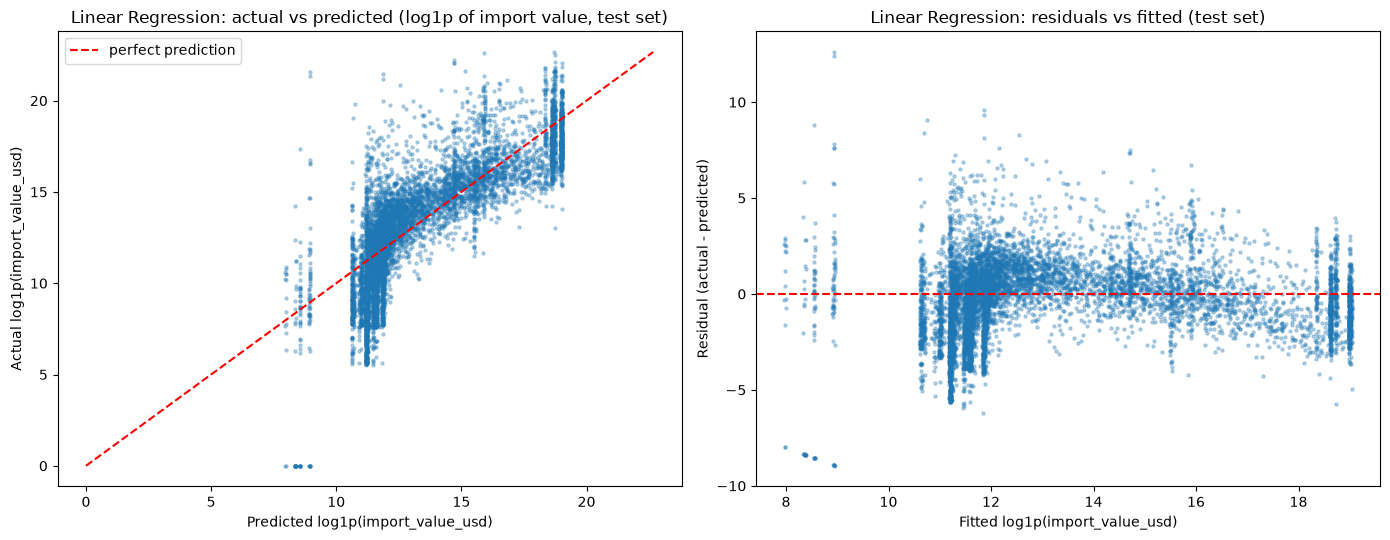

              rows  MAE_log          MAE_usd
band                                        
lowest 20%   16989   2.2600   1,453,509.7340
20-40%       16988   1.6810   1,087,013.7980
40-60%       16988   1.4190   3,464,501.0550
60-80%       16988   1.2160  23,730,362.2070
highest 20%  16989   1.3660 173,482,896.4990


In [13]:
best = results_log["R2"].idxmax()
pred_log = fitted[best][1]
rng = np.random.default_rng(42)
idx = rng.choice(len(y_test_log), size=8000, replace=False)
yt, yp = y_test_log.values[idx], pred_log[idx]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].scatter(yp, yt, s=5, alpha=0.3)
lims = [min(yt.min(), yp.min()), max(yt.max(), yp.max())]
axes[0].plot(lims, lims, "r--", label="perfect prediction")
axes[0].set_title(f"{best}: actual vs predicted (log1p of import value, test set)")
axes[0].set_xlabel("Predicted log1p(import_value_usd)")
axes[0].set_ylabel("Actual log1p(import_value_usd)")
axes[0].legend()

resid = yt - yp
axes[1].scatter(yp, resid, s=5, alpha=0.3)
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set_title(f"{best}: residuals vs fitted (test set)")
axes[1].set_xlabel("Fitted log1p(import_value_usd)")
axes[1].set_ylabel("Residual (actual - predicted)")
plt.tight_layout()
plt.show()

# How does error change across the prediction range?
bands = pd.qcut(pred_log, 5, labels=["lowest 20%", "20-40%", "40-60%", "60-80%", "highest 20%"])
band_err = pd.DataFrame({"band": bands, "abs_err_log": np.abs(y_test_log.values - pred_log),
                         "abs_err_usd": np.abs(y_test.values - np.expm1(pred_log))}).groupby("band", observed=True).agg(
    rows=("abs_err_log", "size"), MAE_log=("abs_err_log", "mean"), MAE_usd=("abs_err_usd", "mean"))
print(band_err.round(3).to_string())

**Is the error consistent across prediction ranges?**
- **On the log scale it is roughly consistent, and slightly better at the top.** Mean absolute error is 2.26 in the lowest fifth of predictions, falls to 1.42 and 1.22 in the middle, and is 1.37 in the highest fifth. The residual plot has no funnel shape.
- **In dollars, the error grows sharply with size.** MAE is about \$1.5M for the lowest fifth and **\$173.5M for the highest fifth**. A log model makes errors of a similar *percentage* at every size, and the same percentage on a \$1B flow is a far bigger dollar amount.

**Two visible patterns:**
- **Vertical stripes around 11.3 to 12 and around 18.7 to 19.** The first is flows with zero or tiny recorded weights. The second is flows whose weights hit the D2 95th percentile cap (32,510 kg air, 325,818 kg vessel). Every capped flow gets about the same prediction, so the model cannot tell a \$300M flow from a \$3B one. That is a real ceiling we built into the data in D2.
- **A small cluster at actual = 0** (the 0.28% of zero-value rows), all overpredicted.

**Interpretation for the best model (Linear Regression, unscaled features, log1p target):**

**RMSE as a percentage of the mean target.** In dollars, RMSE is \$310.8M against a mean test import value of \$40.6M, so **RMSE is 765.6% of the mean**. In plain language, on the dollar scale a typical prediction is off by more than seven times the size of an average flow, and that is driven by the biggest flows. On the log scale, RMSE is 2.06 and MAE is 1.59. Since e^1.59 ≈ 4.9, a typical prediction is off by a factor of about **5** (for example, predicting \$1M for a flow that is really \$200K or \$5M). The log-scale RMSE of 15.8% of mean log value looks small, but it is not a fair comparison, because a log value of 13 already stands for about \$440K.

**R².** On the log scale, R² = **0.6405**: the model explains **64%** of the variation in the order of magnitude of import flows, and **36% is unexplained**. In dollars it explains only **3.6%**, leaving 96.4% unexplained, because a few very large flows make up most of the dollar variation and the weight cap hides exactly those flows.

**Is that acceptable?** Not for decisions in dollars. A procurement team using an RMSE of **10%** could budget on the forecast: if the model said a supplier's monthly flow would be \$20M, they could plan cash, duty payments and inventory around \$18M to \$22M. With RMSE of **50%** they would only use it for direction (growing or shrinking, which suppliers to look into) and would keep a large buffer. At **766% in dollars**, this baseline should not be used to forecast amounts at all. What it is good for is sorting flows into size bands (roughly within 5x) and showing which features matter: weight, mode, duty status and tariff rate. Being a baseline, that is still a useful starting point.

# Part 7: Recommendation

**Recommended baseline for D2: Ridge Regression, unscaled features, log1p target** (test R² 0.6326 on the log scale, 0.0322 in dollars).

**1. Which metric matters most, and why?** **Test R² on the log1p scale**, read together with MAE on the log scale. A procurement team's first question about a supplier flow is its size class: is it \$100K, \$10M or \$1B? That decides how much attention, hedging and duty budget it gets. Log R² measures exactly that, and the models move it from −0.0000 (naive) to 0.63 to 0.64. Dollar RMSE (765.6% of the mean) is driven by a few multi-billion dollar flows, and the D2 weight cap hides what makes them different, so ranking models by dollar error would mostly reward luck on a handful of rows. We still report dollar RMSE% so nobody mistakes this baseline for a budget forecast.

**2. Do the dataset characteristics favour one algorithm?** We have **192,650 training rows and 12 features, about 16,000 rows per feature**, so overfitting is not a risk. Adjusted R² equals R² to four decimals (0.6405 vs 0.6405), and plain Linear Regression has no variance problem for regularisation to fix. That is why Ridge (0.6326) and Lasso (0.6273) do not beat it. The target is extremely right-skewed (skew 24.70 raw), which favours a log target (−0.01 skew) over any choice of algorithm. Lasso's default penalty zeroed 10 of 12 coefficients and kept only the two weights, so at `alpha = 1` it ignores the tariff variables our business question is about.

**3. What did the scaling experiment reveal?** For Ridge and Lasso on the raw dollar target, **nothing changed (0.0509 in both)**, as expected: a penalty of 1 is negligible against dollar-scale errors of about 10²². What we did not expect was that Linear Regression, which should be scale-invariant, changed (0.0552 vs 0.0509). Our features differ in scale by about 10⁷ (std 126,843 vs 0.0192), and scikit-learn's solver quietly dropped 4 of 12 directions (rank 8) on the unscaled data. On the log target, scaling hurt Lasso a lot (0.6273 to 0.5165), because the penalty then lands on comparable, standardised coefficients and shrinks the weight effects. So the experiment showed that the feature scales are so far apart that they change what the solvers do, which is a data property we need to handle (with log weights or scaling plus a tuned alpha) in D2.

**4. Is the best model on paper the most defensible choice?** **No.** Linear Regression has the best log R² (0.6405 vs Ridge's 0.6326, a gap of only 0.0079), but that small edge comes from the rank-8 solution. That solution sets `effective_tariff_rate` to almost zero (+0.0108), so the "best" model has effectively thrown away the tariff signal, the one variable our business question is about. Ridge is full rank and gives the tariff rate a clear coefficient (−7.58, about 7.3% lower value per extra percentage point of tariff), with almost the same accuracy. Ridge also has a penalty we can actually tune in D2. Given the target's skew, no model here should be judged on dollar R² (0.03 to 0.04), but log R² can also flatter a model, because it rewards getting small flows right as much as big ones. That is why we recommend Ridge as the defensible baseline and report both scales.

**Next steps for D2:**
- Tune Ridge's alpha with time-ordered cross-validation.
- Try log-transformed weights. A quick check gave log R² around 0.71.
- Revisit the D2 weight cap, which creates the ceiling seen in the plots.
- Test whether `country` dummies add signal.

# Individual Contributions

| Student Name | Parts Responsible For | Key Decisions Made |
|---|---|---|
| Jashanpreet Singh | All parts (1 to 7) and this contributions section | Removed 7 leakage columns after showing air + vessel value never exceed the target in 100% of rows; chronological 70/30 split at Feb 2025 instead of random; carried the unscaled configuration forward after finding the solver used rank 8 of 12 on unscaled data; chose log1p (skew 24.70 to −0.01, R² 0.64); recommended Ridge over Linear Regression because LR's rank-deficient fit zeroed the tariff coefficient |
| Priyanshu Batra | - | - |
| Janek Basi | - | - |

